In [1]:
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import random
import math
from collections import Counter

print("Bibliothèques importées avec succès.")

Bibliothèques importées avec succès.


In [2]:
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

print("Seed fixé avec succès.")

Seed fixé avec succès.


In [3]:
pairs = [
    ("je suis étudiant", "i am a student"),
    ("je suis professeur", "i am a teacher"),
    ("je suis fatigué", "i am tired"),
    ("je suis heureux", "i am happy"),
    ("tu es étudiant", "you are a student"),
    ("tu es professeur", "you are a teacher"),
    ("il est médecin", "he is a doctor"),
    ("elle est médecin", "she is a doctor"),
    ("nous sommes prêts", "we are ready"),
    ("ils sont prêts", "they are ready"),
    
    ("j aime le deep learning", "i like deep learning"),
    ("j aime python", "i like python"),
    ("j aime les réseaux neuronaux", "i like neural networks"),
    ("tu aimes python", "you like python"),
    ("nous aimons les données", "we like data"),
    
    ("le modèle apprend", "the model learns"),
    ("le modèle prédit", "the model predicts"),
    ("le réseau apprend", "the network learns"),
    ("le réseau prédit", "the network predicts"),
    ("les données sont importantes", "data are important"),
    
    ("ce projet est intéressant", "this project is interesting"),
    ("ce cours est utile", "this course is useful"),
    ("le résultat est bon", "the result is good"),
    ("la précision est élevée", "the accuracy is high"),
    ("la perte diminue", "the loss decreases"),
    
    ("bonjour", "hello"),
    ("merci", "thank you"),
    ("au revoir", "goodbye"),
    ("comment ça va", "how are you"),
    ("je vais bien", "i am fine")
]

print("Nombre de paires :", len(pairs))
pairs[:5]

Nombre de paires : 30


[('je suis étudiant', 'i am a student'),
 ('je suis professeur', 'i am a teacher'),
 ('je suis fatigué', 'i am tired'),
 ('je suis heureux', 'i am happy'),
 ('tu es étudiant', 'you are a student')]

In [4]:
PAD_TOKEN = "<pad>"
BOS_TOKEN = "<bos>"
EOS_TOKEN = "<eos>"
UNK_TOKEN = "<unk>"

special_tokens = [PAD_TOKEN, BOS_TOKEN, EOS_TOKEN, UNK_TOKEN]

In [5]:
def tokenize(sentence):
    return sentence.lower().strip().split()

print(tokenize("je suis étudiant"))

['je', 'suis', 'étudiant']


In [6]:
def build_vocab(sentences):
    counter = Counter()
    
    for sentence in sentences:
        counter.update(tokenize(sentence))
    
    vocab = special_tokens.copy()
    
    for word, freq in counter.items():
        if word not in vocab:
            vocab.append(word)
    
    word2idx = {word: idx for idx, word in enumerate(vocab)}
    idx2word = {idx: word for word, idx in word2idx.items()}
    
    return word2idx, idx2word

src_sentences = [p[0] for p in pairs]
tgt_sentences = [p[1] for p in pairs]

src_word2idx, src_idx2word = build_vocab(src_sentences)
tgt_word2idx, tgt_idx2word = build_vocab(tgt_sentences)

print("Taille vocabulaire source :", len(src_word2idx))
print("Taille vocabulaire cible :", len(tgt_word2idx))

Taille vocabulaire source : 59
Taille vocabulaire cible : 49


In [7]:
def encode_sentence(sentence, word2idx, add_bos=False, add_eos=True):
    tokens = tokenize(sentence)
    ids = []
    
    if add_bos:
        ids.append(word2idx[BOS_TOKEN])
    
    for token in tokens:
        ids.append(word2idx.get(token, word2idx[UNK_TOKEN]))
    
    if add_eos:
        ids.append(word2idx[EOS_TOKEN])
    
    return ids

print(encode_sentence("je suis étudiant", src_word2idx))
print(encode_sentence("i am a student", tgt_word2idx, add_bos=True))

[4, 5, 6, 2]
[1, 4, 5, 6, 7, 2]


In [8]:
def pad_sequence(seq, max_len, pad_idx):
    if len(seq) > max_len:
        return seq[:max_len]
    return seq + [pad_idx] * (max_len - len(seq))

In [9]:
class TranslationDataset(Dataset):
    def __init__(self, pairs, src_word2idx, tgt_word2idx, max_src_len=8, max_tgt_len=8):
        self.pairs = pairs
        self.src_word2idx = src_word2idx
        self.tgt_word2idx = tgt_word2idx
        self.max_src_len = max_src_len
        self.max_tgt_len = max_tgt_len
        
        self.src_pad_idx = src_word2idx[PAD_TOKEN]
        self.tgt_pad_idx = tgt_word2idx[PAD_TOKEN]
    
    def __len__(self):
        return len(self.pairs)
    
    def __getitem__(self, idx):
        src_text, tgt_text = self.pairs[idx]
        
        src_ids = encode_sentence(src_text, self.src_word2idx, add_bos=False, add_eos=True)
        tgt_ids = encode_sentence(tgt_text, self.tgt_word2idx, add_bos=True, add_eos=True)
        
        src_ids = pad_sequence(src_ids, self.max_src_len, self.src_pad_idx)
        tgt_ids = pad_sequence(tgt_ids, self.max_tgt_len, self.tgt_pad_idx)
        
        return torch.tensor(src_ids, dtype=torch.long), torch.tensor(tgt_ids, dtype=torch.long)

In [10]:
dataset = TranslationDataset(pairs, src_word2idx, tgt_word2idx)

train_loader_seq = DataLoader(dataset, batch_size=8, shuffle=True)

src_batch, tgt_batch = next(iter(train_loader_seq))

print("Source batch :", src_batch.shape)
print("Target batch :", tgt_batch.shape)
print(src_batch[0])
print(tgt_batch[0])

Source batch : torch.Size([8, 8])
Target batch : torch.Size([8, 8])
tensor([54, 55, 56,  2,  0,  0,  0,  0])
tensor([ 1, 47, 12, 11,  2,  0,  0,  0])


In [11]:
device_seq = torch.device("cpu")
print("Device utilisé pour les séquences :", device_seq)

Device utilisé pour les séquences : cpu


In [12]:
class Seq2SeqRNN(nn.Module):
    def __init__(self, src_vocab_size, tgt_vocab_size, embed_size=32, hidden_size=64, rnn_type="GRU"):
        super().__init__()
        
        self.rnn_type = rnn_type.upper()
        self.hidden_size = hidden_size
        
        self.src_embedding = nn.Embedding(src_vocab_size, embed_size, padding_idx=src_word2idx[PAD_TOKEN])
        self.tgt_embedding = nn.Embedding(tgt_vocab_size, embed_size, padding_idx=tgt_word2idx[PAD_TOKEN])
        
        if self.rnn_type == "RNN":
            self.encoder = nn.RNN(embed_size, hidden_size, batch_first=True)
            self.decoder = nn.RNN(embed_size, hidden_size, batch_first=True)
        elif self.rnn_type == "LSTM":
            self.encoder = nn.LSTM(embed_size, hidden_size, batch_first=True)
            self.decoder = nn.LSTM(embed_size, hidden_size, batch_first=True)
        elif self.rnn_type == "GRU":
            self.encoder = nn.GRU(embed_size, hidden_size, batch_first=True)
            self.decoder = nn.GRU(embed_size, hidden_size, batch_first=True)
        else:
            raise ValueError("rnn_type doit être RNN, LSTM ou GRU")
        
        self.fc_out = nn.Linear(hidden_size, tgt_vocab_size)
    
    def forward(self, src, tgt_input):
        # Encodage de la phrase source
        src_emb = self.src_embedding(src)
        encoder_outputs, encoder_hidden = self.encoder(src_emb)
        
        # Décodage de la phrase cible avec teacher forcing
        tgt_emb = self.tgt_embedding(tgt_input)
        decoder_outputs, decoder_hidden = self.decoder(tgt_emb, encoder_hidden)
        
        logits = self.fc_out(decoder_outputs)
        return logits

In [13]:
src_vocab_size = len(src_word2idx)
tgt_vocab_size = len(tgt_word2idx)

model_gru = Seq2SeqRNN(
    src_vocab_size=src_vocab_size,
    tgt_vocab_size=tgt_vocab_size,
    rnn_type="GRU"
).to(device_seq)

src_batch, tgt_batch = next(iter(train_loader_seq))

src_batch = src_batch.to(device_seq)
tgt_batch = tgt_batch.to(device_seq)

tgt_input = tgt_batch[:, :-1]
tgt_output = tgt_batch[:, 1:]

logits = model_gru(src_batch, tgt_input)

print("Logits :", logits.shape)
print("Target output :", tgt_output.shape)

Logits : torch.Size([8, 7, 49])
Target output : torch.Size([8, 7])


In [14]:
def train_seq2seq(model, data_loader, num_epochs=200, lr=0.01):
    model = model.to(device_seq)
    
    pad_idx = tgt_word2idx[PAD_TOKEN]
    criterion = nn.CrossEntropyLoss(ignore_index=pad_idx)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    
    losses = []
    
    for epoch in range(num_epochs):
        model.train()
        total_loss = 0
        
        for src_batch, tgt_batch in data_loader:
            src_batch = src_batch.to(device_seq)
            tgt_batch = tgt_batch.to(device_seq)
            
            tgt_input = tgt_batch[:, :-1]
            tgt_output = tgt_batch[:, 1:]
            
            optimizer.zero_grad()
            
            logits = model(src_batch, tgt_input)
            
            loss = criterion(
                logits.reshape(-1, logits.shape[-1]),
                tgt_output.reshape(-1)
            )
            
            loss.backward()
            
            # Gradient clipping pour éviter l'explosion du gradient
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            
            optimizer.step()
            
            total_loss += loss.item()
        
        avg_loss = total_loss / len(data_loader)
        losses.append(avg_loss)
        
        if (epoch + 1) % 20 == 0:
            print(f"Epoch [{epoch+1}/{num_epochs}] | Loss: {avg_loss:.4f}")
    
    return losses

In [15]:
losses_gru = train_seq2seq(
    model_gru,
    train_loader_seq,
    num_epochs=200,
    lr=0.01
)

Epoch [20/200] | Loss: 0.1320
Epoch [40/200] | Loss: 0.0240
Epoch [60/200] | Loss: 0.0062
Epoch [80/200] | Loss: 0.0036
Epoch [100/200] | Loss: 0.0024
Epoch [120/200] | Loss: 0.0017
Epoch [140/200] | Loss: 0.0014
Epoch [160/200] | Loss: 0.0011
Epoch [180/200] | Loss: 0.0009
Epoch [200/200] | Loss: 0.0007


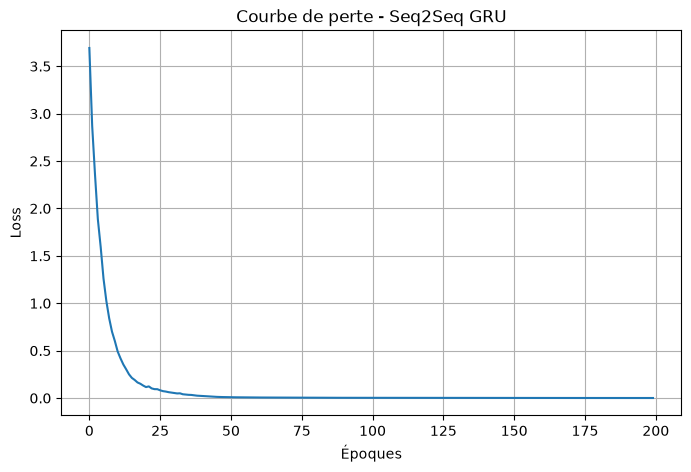

In [16]:
plt.figure(figsize=(8,5))
plt.plot(losses_gru)
plt.xlabel("Époques")
plt.ylabel("Loss")
plt.title("Courbe de perte - Seq2Seq GRU")
plt.grid(True)
plt.show()

In [17]:
def translate_greedy(model, sentence, max_len=8):
    model.eval()
    
    src_ids = encode_sentence(sentence, src_word2idx, add_bos=False, add_eos=True)
    src_ids = pad_sequence(src_ids, 8, src_word2idx[PAD_TOKEN])
    
    src_tensor = torch.tensor(src_ids, dtype=torch.long).unsqueeze(0).to(device_seq)
    
    with torch.no_grad():
        src_emb = model.src_embedding(src_tensor)
        encoder_outputs, hidden = model.encoder(src_emb)
        
        current_token = torch.tensor([[tgt_word2idx[BOS_TOKEN]]], dtype=torch.long).to(device_seq)
        
        output_words = []
        
        for _ in range(max_len):
            tgt_emb = model.tgt_embedding(current_token)
            decoder_output, hidden = model.decoder(tgt_emb, hidden)
            logits = model.fc_out(decoder_output[:, -1, :])
            
            pred_id = torch.argmax(logits, dim=1).item()
            pred_word = tgt_idx2word[pred_id]
            
            if pred_word == EOS_TOKEN:
                break
            
            if pred_word not in [PAD_TOKEN, BOS_TOKEN]:
                output_words.append(pred_word)
            
            current_token = torch.tensor([[pred_id]], dtype=torch.long).to(device_seq)
    
    return " ".join(output_words)

In [18]:
test_sentences = [
    "je suis étudiant",
    "j aime python",
    "le modèle apprend",
    "ce projet est intéressant",
    "merci"
]

for sentence in test_sentences:
    translation = translate_greedy(model_gru, sentence)
    print(f"{sentence}  -->  {translation}")

je suis étudiant  -->  i am a student
j aime python  -->  i like python
le modèle apprend  -->  the model learns
ce projet est intéressant  -->  this project is interesting
merci  -->  thank you


In [19]:
model_rnn = Seq2SeqRNN(
    src_vocab_size=src_vocab_size,
    tgt_vocab_size=tgt_vocab_size,
    rnn_type="RNN"
).to(device_seq)

model_lstm = Seq2SeqRNN(
    src_vocab_size=src_vocab_size,
    tgt_vocab_size=tgt_vocab_size,
    rnn_type="LSTM"
).to(device_seq)

model_gru_compare = Seq2SeqRNN(
    src_vocab_size=src_vocab_size,
    tgt_vocab_size=tgt_vocab_size,
    rnn_type="GRU"
).to(device_seq)

print("Entraînement RNN")
losses_rnn = train_seq2seq(model_rnn, train_loader_seq, num_epochs=150, lr=0.01)

print("Entraînement LSTM")
losses_lstm = train_seq2seq(model_lstm, train_loader_seq, num_epochs=150, lr=0.01)

print("Entraînement GRU")
losses_gru_compare = train_seq2seq(model_gru_compare, train_loader_seq, num_epochs=150, lr=0.01)

Entraînement RNN
Epoch [20/150] | Loss: 0.3812
Epoch [40/150] | Loss: 0.2044
Epoch [60/150] | Loss: 0.1717
Epoch [80/150] | Loss: 0.0982
Epoch [100/150] | Loss: 0.0809
Epoch [120/150] | Loss: 0.1338
Epoch [140/150] | Loss: 0.1103
Entraînement LSTM
Epoch [20/150] | Loss: 0.2465
Epoch [40/150] | Loss: 0.0703
Epoch [60/150] | Loss: 0.0137
Epoch [80/150] | Loss: 0.0051
Epoch [100/150] | Loss: 0.0033
Epoch [120/150] | Loss: 0.0023
Epoch [140/150] | Loss: 0.0017
Entraînement GRU
Epoch [20/150] | Loss: 0.1537
Epoch [40/150] | Loss: 0.0448
Epoch [60/150] | Loss: 0.0064
Epoch [80/150] | Loss: 0.0036
Epoch [100/150] | Loss: 0.0023
Epoch [120/150] | Loss: 0.0017
Epoch [140/150] | Loss: 0.0013


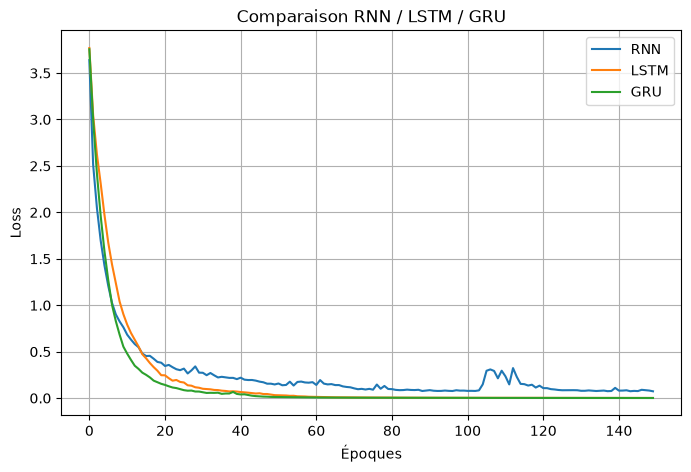

In [20]:
plt.figure(figsize=(8,5))
plt.plot(losses_rnn, label="RNN")
plt.plot(losses_lstm, label="LSTM")
plt.plot(losses_gru_compare, label="GRU")
plt.xlabel("Époques")
plt.ylabel("Loss")
plt.title("Comparaison RNN / LSTM / GRU")
plt.legend()
plt.grid(True)
plt.show()

In [21]:
comparison_seq = pd.DataFrame({
    "Modèle": ["RNN", "LSTM", "GRU"],
    "Loss finale": [
        round(losses_rnn[-1], 4),
        round(losses_lstm[-1], 4),
        round(losses_gru_compare[-1], 4)
    ]
})

comparison_seq

,Modèle,Loss finale
0,RNN,0.0733
1,LSTM,0.0015
2,GRU,0.0012


In [22]:
test_sentences = [
    "je suis étudiant",
    "j aime python",
    "le modèle apprend",
    "ce projet est intéressant",
    "merci"
]

for sentence in test_sentences:
    print("Phrase source :", sentence)
    print("RNN  :", translate_greedy(model_rnn, sentence))
    print("LSTM :", translate_greedy(model_lstm, sentence))
    print("GRU  :", translate_greedy(model_gru_compare, sentence))
    print("-" * 50)

Phrase source : je suis étudiant
RNN  : i am a student
LSTM : i am a student
GRU  : i am a student
--------------------------------------------------
Phrase source : j aime python
RNN  : i like python
LSTM : i like python
GRU  : i like python
--------------------------------------------------
Phrase source : le modèle apprend
RNN  : the model learns
LSTM : the model learns
GRU  : the model learns
--------------------------------------------------
Phrase source : ce projet est intéressant
RNN  : this project is interesting
LSTM : this project is interesting
GRU  : this project is interesting
--------------------------------------------------
Phrase source : merci
RNN  : thank you
LSTM : thank you
GRU  : thank you
--------------------------------------------------


In [23]:
import torch.nn.functional as F

def clone_hidden(hidden):
    if isinstance(hidden, tuple):
        return tuple(h.clone() for h in hidden)
    return hidden.clone()

def translate_beam_search(model, sentence, beam_width=3, max_len=8):
    model.eval()
    
    src_ids = encode_sentence(sentence, src_word2idx, add_bos=False, add_eos=True)
    src_ids = pad_sequence(src_ids, 8, src_word2idx[PAD_TOKEN])
    src_tensor = torch.tensor(src_ids, dtype=torch.long).unsqueeze(0).to(device_seq)
    
    with torch.no_grad():
        src_emb = model.src_embedding(src_tensor)
        encoder_outputs, hidden = model.encoder(src_emb)
        
        bos_id = tgt_word2idx[BOS_TOKEN]
        eos_id = tgt_word2idx[EOS_TOKEN]
        
        beams = [([bos_id], 0.0, hidden)]
        completed = []
        
        for _ in range(max_len):
            new_beams = []
            
            for tokens, score, hidden_state in beams:
                last_token = tokens[-1]
                
                if last_token == eos_id:
                    completed.append((tokens, score))
                    continue
                
                current_token = torch.tensor([[last_token]], dtype=torch.long).to(device_seq)
                tgt_emb = model.tgt_embedding(current_token)
                
                decoder_output, new_hidden = model.decoder(tgt_emb, hidden_state)
                logits = model.fc_out(decoder_output[:, -1, :])
                log_probs = F.log_softmax(logits, dim=-1)
                
                top_log_probs, top_ids = torch.topk(log_probs, beam_width)
                
                for i in range(beam_width):
                    next_id = top_ids[0, i].item()
                    next_score = score + top_log_probs[0, i].item()
                    new_tokens = tokens + [next_id]
                    new_beams.append((new_tokens, next_score, clone_hidden(new_hidden)))
            
            beams = sorted(new_beams, key=lambda x: x[1], reverse=True)[:beam_width]
        
        completed.extend([(tokens, score) for tokens, score, _ in beams])
        best_tokens, best_score = sorted(completed, key=lambda x: x[1], reverse=True)[0]
        
        words = []
        for idx in best_tokens:
            word = tgt_idx2word[idx]
            if word in [BOS_TOKEN, PAD_TOKEN]:
                continue
            if word == EOS_TOKEN:
                break
            words.append(word)
        
        return " ".join(words)

In [24]:
for sentence in test_sentences:
    greedy_translation = translate_greedy(model_gru_compare, sentence)
    beam_translation = translate_beam_search(model_gru_compare, sentence, beam_width=3)
    
    print("Phrase source :", sentence)
    print("Greedy     :", greedy_translation)
    print("Beam Search:", beam_translation)
    print("-" * 50)

Phrase source : je suis étudiant
Greedy     : i am a student
Beam Search: i am a student
--------------------------------------------------
Phrase source : j aime python
Greedy     : i like python
Beam Search: i like python
--------------------------------------------------
Phrase source : le modèle apprend
Greedy     : the model learns
Beam Search: the model learns
--------------------------------------------------
Phrase source : ce projet est intéressant
Greedy     : this project is interesting
Beam Search: this project is interesting
--------------------------------------------------
Phrase source : merci
Greedy     : thank you
Beam Search: thank you
--------------------------------------------------


### Analyse comparative des modèles RNN, LSTM et GRU

Dans cette partie, trois architectures séquentielles ont été comparées : RNN simple, LSTM et GRU. Les modèles ont été entraînés sur un mini-corpus parallèle français-anglais afin de réaliser une tâche de traduction automatique simplifiée avec une architecture Seq2Seq.

Les résultats montrent que le RNN simple réduit progressivement sa fonction de perte, mais reste moins stable que les architectures à portes. Le LSTM et le GRU atteignent une perte finale beaucoup plus faible, ce qui indique une meilleure capacité d’apprentissage sur les séquences du corpus.

Cette différence s’explique par la structure interne des modèles. Le RNN simple transmet uniquement un état caché d’un pas de temps au suivant, ce qui peut entraîner des problèmes de gradient évanescent ou explosif lors de la rétropropagation à travers le temps. À l’inverse, le LSTM utilise des portes d’entrée, d’oubli et de sortie, tandis que le GRU utilise une porte de mise à jour et une porte de réinitialisation. Ces mécanismes permettent de mieux contrôler la mémoire et de conserver l’information utile sur plusieurs pas de temps.

Dans cette expérimentation, le GRU obtient la perte finale la plus faible, suivi de près par le LSTM. Le GRU constitue donc un bon compromis entre performance et simplicité, car il possède moins de paramètres que le LSTM tout en conservant une bonne capacité de mémorisation.

Le décodage glouton et le beam search ont également été testés. Le décodage glouton choisit à chaque étape le mot le plus probable, tandis que le beam search conserve plusieurs hypothèses candidates. Le beam search est donc plus coûteux, mais il peut produire de meilleures séquences lorsque plusieurs traductions sont possibles.


In [25]:
def simple_bleu(reference, prediction):
    """
    Score BLEU simplifié basé sur le recouvrement des mots.
    Ce n'est pas le BLEU officiel complet, mais il permet une évaluation pédagogique.
    """
    ref_tokens = reference.split()
    pred_tokens = prediction.split()
    
    if len(pred_tokens) == 0:
        return 0.0
    
    common = 0
    ref_counts = Counter(ref_tokens)
    
    for token in pred_tokens:
        if ref_counts[token] > 0:
            common += 1
            ref_counts[token] -= 1
    
    precision = common / len(pred_tokens)
    
    # pénalité simple si la phrase prédite est trop courte
    brevity_penalty = min(1.0, len(pred_tokens) / len(ref_tokens))
    
    return precision * brevity_penalty

In [26]:
bleu_scores = []

for src, tgt in pairs:
    pred = translate_greedy(model_gru_compare, src)
    score = simple_bleu(tgt, pred)
    bleu_scores.append(score)

average_bleu = sum(bleu_scores) / len(bleu_scores)

print("Score BLEU simplifié moyen :", round(average_bleu, 4))

Score BLEU simplifié moyen : 1.0


In [27]:
torch.save(model_rnn.state_dict(), "seq2seq_rnn.pth")
torch.save(model_lstm.state_dict(), "seq2seq_lstm.pth")
torch.save(model_gru_compare.state_dict(), "seq2seq_gru.pth")

print("Modèles RNN, LSTM et GRU sauvegardés avec succès.")

Modèles RNN, LSTM et GRU sauvegardés avec succès.


### Résultats de traduction et analyse du décodage

Le modèle Seq2Seq basé sur GRU a été testé sur plusieurs phrases du mini-corpus français-anglais. Les traductions obtenues sont correctes :

| Phrase source             | Traduction générée          |
| ------------------------- | --------------------------- |
| je suis étudiant          | i am a student              |
| j aime python             | i like python               |
| le modèle apprend         | the model learns            |
| ce projet est intéressant | this project is interesting |
| merci                     | thank you                   |

Le décodage glouton et le beam search donnent les mêmes résultats sur ces exemples. Cela s’explique par la simplicité du corpus et par le fait que les phrases sont courtes et peu ambiguës. Dans un corpus plus grand, le beam search pourrait devenir plus utile, car il explore plusieurs hypothèses de traduction au lieu de choisir uniquement le mot le plus probable à chaque étape.

Les résultats montrent que le modèle GRU a bien appris les correspondances entre les phrases sources et cibles. Toutefois, cette performance doit être interprétée avec prudence, car le corpus utilisé est réduit. Le modèle peut donc mémoriser les exemples plutôt que généraliser réellement à des phrases nouvelles. Pour améliorer l’évaluation, il serait nécessaire d’utiliser un corpus plus grand, comme Tatoeba ou un corpus parallèle français-anglais, avec une séparation claire entre apprentissage, validation et test.

Cette expérience reste néanmoins pertinente pédagogiquement, car elle permet de comprendre les étapes fondamentales d’un système Seq2Seq : tokenisation, construction du vocabulaire, padding, encodage, décodage, teacher forcing, gradient clipping et génération auto-régressive.


### Réponse à la question de synthèse – Partie III

Les architectures récurrentes permettent de modéliser efficacement les séquences, car elles prennent en compte l’ordre des éléments. Contrairement à un MLP, qui traite les données comme un vecteur fixe, un RNN lit la séquence étape par étape et transmet un état caché représentant le contexte déjà observé.

Le RNN simple constitue une première solution pour les données séquentielles, mais il présente des limites importantes. Lors de la rétropropagation à travers le temps, les gradients peuvent devenir très faibles ou très grands, ce qui rend l’apprentissage instable. Dans nos résultats expérimentaux, le RNN réduit bien sa perte, mais il reste moins performant que le LSTM et le GRU.

Le LSTM améliore cette situation grâce à ses portes d’entrée, d’oubli et de sortie. Ces portes contrôlent l’information à mémoriser, à oublier et à transmettre. Le GRU propose une version plus simple, avec une porte de mise à jour et une porte de réinitialisation. Dans notre expérience, le GRU obtient la perte finale la plus faible, ce qui montre qu’il représente un bon compromis entre performance et simplicité.

Le passage vers une architecture encodeur-décodeur se justifie lorsqu’on cherche à transformer une séquence source en une séquence cible, comme dans la traduction automatique. L’encodeur lit la phrase source et produit une représentation interne, tandis que le décodeur génère progressivement la phrase cible. Le teacher forcing facilite l’apprentissage en fournissant au décodeur le vrai mot précédent pendant l’entraînement.

Enfin, le décodage joue un rôle important. Le décodage glouton est rapide mais limité, car il choisit uniquement le mot le plus probable à chaque étape. Le beam search est plus coûteux, mais il explore plusieurs hypothèses et peut produire de meilleures traductions dans des tâches plus complexes.


### Analyse du score BLEU simplifié

Le modèle GRU Seq2Seq obtient un score BLEU simplifié moyen de 1.0 sur le mini-corpus utilisé. Ce résultat signifie que les traductions générées correspondent parfaitement aux phrases de référence dans cette expérience.

Cependant, ce score doit être interprété avec prudence. Le corpus utilisé est réduit et les phrases sont courtes, simples et peu ambiguës. Le modèle a donc probablement mémorisé les correspondances entre phrases sources et phrases cibles. Dans un contexte réel, il serait nécessaire d’utiliser un corpus plus large, avec une séparation stricte entre apprentissage, validation et test.

Ainsi, le score BLEU de 1.0 montre que l’architecture Seq2Seq fonctionne correctement sur un exemple pédagogique, mais il ne suffit pas à prouver une capacité de généralisation sur des phrases nouvelles ou complexes.


### Discussion transversale finale

Ce projet a permis d’étudier trois grandes familles d’architectures de deep learning : le MLP pour les données tabulaires, le CNN pour les images et les modèles récurrents pour les séquences. Ces architectures reposent toutes sur le même principe général d’apprentissage supervisé : apprendre une fonction de prédiction à partir d’exemples annotés. Cependant, elles se différencient fortement par leur manière de représenter les données.

Dans la première partie, le MLP a été appliqué à un dataset tabulaire. Ce type d’architecture est adapté lorsque les données sont représentées sous forme de variables numériques ou catégorielles structurées. Le MLP apprend des relations non linéaires entre les variables, mais il ne possède pas de biais inductif particulier. Il ne tient pas compte d’une structure spatiale ou temporelle. Les résultats obtenus sur le dataset Breast Cancer Wisconsin montrent qu’un MLP bien paramétré, avec normalisation, dropout et initialisation adaptée, peut atteindre de très bonnes performances sur des données tabulaires.

Dans la deuxième partie, les CNN ont été utilisés pour la classification d’images avec Fashion-MNIST. Contrairement au MLP, qui aplatit l’image en vecteur, le CNN conserve l’organisation spatiale des pixels. Les filtres convolutionnels exploitent la localité, le partage des poids et la hiérarchie des représentations. Les premières couches détectent des motifs simples comme les contours, tandis que les couches plus profondes combinent ces motifs pour reconnaître des formes plus complexes. Même si le MLP a obtenu un meilleur score dans notre expérience, le CNN reste théoriquement plus adapté aux images, car il respecte la géométrie des données visuelles.

Dans la troisième partie, les modèles RNN, LSTM et GRU ont été appliqués à des séquences textuelles dans une tâche de traduction automatique simplifiée. Les données séquentielles se distinguent par l’importance de l’ordre des éléments. Un mot ou un token ne peut pas être interprété indépendamment de son contexte. Les RNN introduisent donc un état caché transmis dans le temps. Toutefois, les RNN simples souffrent de limites liées aux gradients évanescents ou explosifs. Les LSTM et GRU corrigent partiellement ces limites grâce à des mécanismes de portes qui contrôlent la mémoire. Dans notre expérience, le GRU a obtenu la perte finale la plus faible, ce qui confirme son efficacité et sa simplicité.

La comparaison globale montre que le choix de l’architecture dépend fortement de la nature des données. Pour des données tabulaires, le MLP est souvent suffisant. Pour des images, le CNN est conceptuellement plus approprié, car il exploite les relations locales entre pixels. Pour des séquences, les modèles récurrents sont nécessaires afin de prendre en compte l’ordre et la dépendance temporelle.

Ainsi, un même paradigme d’apprentissage supervisé doit être décliné différemment selon la structure des données. La performance ne dépend pas seulement de l’algorithme, mais aussi du prétraitement, de la représentation des données, de l’architecture choisie, des hyperparamètres, du nombre d’époques et de la qualité de l’analyse expérimentale.
